In [1]:
import pandas as pd
import yfinance as yf
import numpy as np



# 1. Download dati giornalieri, 8 anni
ticker = "DOGE-USD"
df = yf.download(ticker, period="8y", interval="1d")

# Pulizia del MultiIndex
if isinstance(df.columns, pd.MultiIndex):
    df.columns = df.columns.get_level_values(0)

[*********************100%***********************]  1 of 1 completed


In [2]:
# 2. Calcolo degli indicatori di base
window = 30  # Finestra di 30 giorni per la media mobile dei volumi
df["Volume_MA"] = df["Volume"].rolling(window=window).mean()
df["Volume_STD"] = df["Volume"].rolling(window=window).std()

# Variazione percentuale giornaliera del prezzo
df["Price_Change_Pct"] = df["Close"].pct_change() * 100

# MEDIA MOBILE A 7 GIORNI FINO AL GIORNO -1 (Spostata di 1 giorno nel passato per non essere influenzato dal Pump)
# Usiamo il valore assoluto per misurare l'ampiezza media dell'oscillazione giornaliera recente
df["Price_Change_Abs_MA7_Lag1"] = (
    df["Price_Change_Pct"].abs().shift(1).rolling(window=7).mean()
)

# 3. Definizione delle condizioni di "Pump", per essere considerato pump deve avere:
# - Volume superiore alla media + 4 volte la deviazione standard
# - Rialzo del prezzo giornaliero superiore al 15%
df["Volume_Anomaly"] = df["Volume"] > (df["Volume_MA"] + (4 * df["Volume_STD"]))
df["Pump_Candidate"] = df["Volume_Anomaly"] & (df["Price_Change_Pct"] > 15)

pumps = df[df["Pump_Candidate"]]

print(
    f"Trovati {len(pumps)} giorni con caratteristiche sospette di pump su {ticker}:"
)
print(
    pumps[
        [
            "Close",
            "Price_Change_Pct",
            "Price_Change_Abs_MA7_Lag1",
            "Volume",
            "Volume_MA",
        ]
    ]
)

Trovati 19 giorni con caratteristiche sospette di pump su DOGE-USD:
Price          Close  Price_Change_Pct  Price_Change_Abs_MA7_Lag1  \
Date                                                                
2019-04-01  0.002461         18.317313                   0.581861   
2019-04-04  0.003697         16.845760                   6.654426   
2019-07-05  0.003867         19.758446                   2.741483   
2020-07-08  0.004750         53.721677                   5.055169   
2020-11-24  0.004204         15.241223                   5.344775   
2020-12-20  0.004625         17.774388                   3.634886   
2021-01-02  0.010615         86.719422                   4.593773   
2021-01-28  0.034084        355.546631                   4.493524   
2021-01-29  0.047162         38.369911                  53.876250   
2021-04-01  0.061986         15.522673                   1.255150   
2021-04-14  0.121517         30.041199                  10.082971   
2021-04-16  0.365870        100.799

Già dai grafici di volume e prezzo si può intuire una correlazione tra volume e prezzo

In [27]:
results = []
for date in pumps.index:
  idx = df.index.get_loc(date)

  # Prendiamo i prezzi dei 3 giorni successivi
  if idx + 3 < len(df):
    close_day_0 = df.loc[date, "Close"]
    close_day_1 = df.iloc[idx + 1]["Close"]
    close_day_3 = df.iloc[idx + 3]["Close"]

    return_1d = ((close_day_1 - close_day_0) / close_day_0) * 100
    return_3d = ((close_day_3 - close_day_0) / close_day_0) * 100
    pump_return = df.loc[date, "Price_Change_Pct"]

    # Estraiamo la media mobile a 7 giorni del giorno precedente (t-1)
    normal_volatility_ma7 = df.loc[date, "Price_Change_Abs_MA7_Lag1"]

    gain_retained_ratio = return_3d / pump_return if pump_return != 0 else 0

    results.append({
        "Date": date,
        "Pump_Return": pump_return,
        "Return_Day_1": return_1d,
        "Return_Day_3": return_3d,
        "Gain": gain_retained_ratio,
        "Volat_MA7": (
            normal_volatility_ma7  # <--- Aggiunto nel dizionario
        ),
    })

df_analysis = pd.DataFrame(results)
print(df_analysis)

         Date  Pump_Return  Return_Day_1  Return_Day_3      Gain  Volat_MA7
0  2019-04-01    18.317313     13.571717     50.223479  2.741858   0.581861
1  2019-04-04    16.845760     -2.894235     -7.546660 -0.447986   6.654426
2  2019-07-05    19.758446     -8.275151     -7.964831 -0.403110   2.741483
3  2020-07-08    53.721677     -7.431572    -19.768420 -0.367978   5.055169
4  2020-11-24    15.241223    -11.346335    -22.097999 -1.449884   5.344775
5  2020-12-20    17.774388      3.502699    -18.529730 -1.042496   3.634886
6  2021-01-02    86.719422     -7.951012     -6.547334 -0.075500   4.593773
7  2021-01-28   355.546631     38.369911      9.130382  0.025680   4.493524
8  2021-01-29    38.369911    -40.256986    -26.052751 -0.678989  53.876250
9  2021-04-01    15.522673     -6.972542     -7.391990 -0.476206   1.255150
10 2021-04-14    30.041199     49.943629    133.854527  4.455699  10.082971
11 2021-04-16   100.799087    -22.329513     11.328613  0.112388  19.716383
12 2021-10-2

In [28]:
def classify_dump_v4(row):
  pump = row["Pump_Return"]
  ret_3d = row["Return_Day_3"]
  ratio = row["Gain"]
  normal_vol = row["Volat_MA7"]

  # REGOLA: Se a 3 giorni il prezzo è in positivo, NON è un dump
  if ret_3d > 0:
    return False

  # Esempio di utilizzo dinamico della volatilità normale:
  # Richiediamo che l'entità del calo a 3 giorni superi un multiplo della normale escursione giornaliera
  # (oppure manteniamo le soglie percentuali fisse combinate con la volatilità di fondo)

  if pump <= 50:
    # Per pump moderati: dump se va in rosso e il calo supera la volatilità normale o perde metà guadagno
    return (ret_3d < -5.0) or (ratio < 0.5)

  elif 50 < pump <= 150:
    # Per pump grandi: richiede crollo marcato
    return (ret_3d < -12.0) and (ratio < 0.0)

  else:
    # Per i mega-movimenti (> 150%): crolli devastanti
    return ret_3d < -20.0


df_analysis["Is_True_Dump"] = df_analysis.apply(classify_dump_v4, axis=1)
true_pumps_and_dumps = df_analysis[df_analysis["Is_True_Dump"]]

print(
    f"Eventi con effettivo 'Dump' ripulito (con Volatilità Normale):"
    f" {len(true_pumps_and_dumps)} su {len(df_analysis)}"
)

print(
    true_pumps_and_dumps[
        [
            "Date",
            "Pump_Return",
            "Return_Day_3",
            "Gain",
            "Volat_MA7",
        ]
    ]
)

Eventi con effettivo 'Dump' ripulito (con Volatilità Normale): 10 su 19
         Date  Pump_Return  Return_Day_3      Gain  Volat_MA7
1  2019-04-04    16.845760     -7.546660 -0.447986   6.654426
2  2019-07-05    19.758446     -7.964831 -0.403110   2.741483
3  2020-07-08    53.721677    -19.768420 -0.367978   5.055169
4  2020-11-24    15.241223    -22.097999 -1.449884   5.344775
5  2020-12-20    17.774388    -18.529730 -1.042496   3.634886
8  2021-01-29    38.369911    -26.052751 -0.678989  53.876250
9  2021-04-01    15.522673     -7.391990 -0.476206   1.255150
12 2021-10-28    26.402871     -6.724313 -0.254681   4.770372
13 2022-04-05    16.364382    -17.557417 -1.072904   2.431638
16 2023-04-03    21.482126    -11.102318 -0.516817   3.765473


In [33]:
results = []
for date in pumps.index:
  idx = df.index.get_loc(date)

  if idx + 3 < len(df):
    close_day_minus1 = df.iloc[idx - 1]["Close"] if idx > 0 else df.iloc[idx]["Close"]
    close_day_0 = df.loc[date, "Close"]
    close_day_3 = df.iloc[idx + 3]["Close"]

    pump_return = df.loc[date, "Price_Change_Pct"]
    return_3d = ((close_day_3 - close_day_0) / close_day_0) * 100

    # Calcolo del guadagno totale generato dal pump in dollari/valore
    total_pump_gain = close_day_0 - close_day_minus1
    
    # Guadagno rimasto al giorno 3
    remaining_gain = close_day_3 - close_day_minus1

    # Ratio basato sui prezzi effettivi (più robusto)
    # Se remaining_gain / total_pump_gain <= 0.3, significa che ha perso >= 70% del guadagno
    retained_price_ratio = remaining_gain / total_pump_gain if total_pump_gain != 0 else 0

    # FILTRO RIGOROSO:
    # 1. Il pump deve essere > 15%
    # 2. Il prezzo al giorno 3 deve essere SCESO rispetto al giorno 0 (Return_Day_3 < 0)
    # 3. Deve aver perso almeno il 70% del guadagno fatto (retained_price_ratio <= 0.3)
    is_true_70pct_dump = (pump_return > 15.0) and (return_3d < 0) and (retained_price_ratio <= 0.3)

    if is_true_70pct_dump:
      results.append({
          "Date": date,
          "Pump_Return": pump_return,
          "Return_Day_3": return_3d,
          "Gain": retained_price_ratio,
          "Volat_MA7": df.loc[date, "Price_Change_Abs_MA7_Lag1"],
      })

df_strict_dumps = pd.DataFrame(results)

print(f"=== PUMP & DUMP AGGRESSIVI CON PERDITA >= 70% ({len(df_strict_dumps)} totali) ===")
print(df_strict_dumps.to_string(index=False))

=== PUMP & DUMP AGGRESSIVI CON PERDITA >= 70% (4 totali) ===
      Date  Pump_Return  Return_Day_3      Gain  Volat_MA7
2020-11-24    15.241223    -22.097999 -0.670864   5.344775
2020-12-20    17.774388    -18.529730 -0.227793   3.634886
2021-01-29    38.369911    -26.052751  0.060483  53.876250
2022-04-05    16.364382    -17.557417 -0.248479   2.431638


Questi sono i giorni in cui dopo una salita di prezzo distanti 4 volte dalla deviazione standard, nel giro di 3 giorni perde oltre il 70% del guadagno


2020-01-29 (Pump del +38%, Dump del -26%):
- Contesto: È il giorno successivo al culmine della primissima grande mania innescata da WallStreetBets e dai tweet virali coordinati su Elon Musk, che spinsero il prezzo a ridosso dei massimi di quel periodo prima di un violento scarico. La volatilità di fondo era infatti schizzata alle stelle (53.88%). 
Corrisponde esattamente all'epicentro della storica bolla di fine gennaio 2021 guidata da Reddit (WallStreetBets) e dai ripetuti tweet di Elon Musk, dove Dogecoin registrò volumi e movimenti record seguiti da un immediato sell-off.

2020-11-24 e 2020-12-20:
- Contesto: Dicembre 2020 segna storicamente il primo tweet in assoluto di Elon Musk focalizzato esplicitamente su Dogecoin ("One Word: Doge" il 20 dicembre 2020), che fece impennare immediatamente il token prima del riassorbimento fisiologico dei prezzi.



In [8]:
# 1. Individuiamo la data e l'indice del massimo storico (il picco del 2021)
peak_date = df.loc["2021-04-01":"2021-06-30"]["Close"].idxmax()
peak_idx = df.index.get_loc(peak_date)
peak_price = df.loc[peak_date, "Close"]

print(f"=== ANALISI DISCESA POST-PICCO 2021 (Target: $0.20) ===")
print(f"Data del picco massimo: {peak_date.strftime('%Y-%m-%d')}")
print(f"Prezzo massimo: $ {peak_price:.4f}\n")

# 2. Scansioniamo in avanti giorno per giorno per trovare quando scende sotto 0.20$
target_price = 0.20
days_to_target = None
max_days_to_check = 365  # Cerchiamo fino a un anno dopo

for offset in range(1, max_days_to_check + 1):
  if peak_idx + offset < len(df):
    current_date = df.index[peak_idx + offset]
    current_close = df.iloc[peak_idx + offset]["Close"]

    # Appena il prezzo tocca o scende sotto i 20 centesimi
    if current_close <= target_price:
      days_to_target = offset
      target_date = current_date
      final_price_at_target = current_close
      break
  else:
    break

if days_to_target is not None:
  print(
      f"Il prezzo è tornato sotto i $0.20 dopo **{days_to_target} giorni** dal"
      f" picco."
  )
  print(f"Data esatta: {target_date.strftime('%Y-%m-%d')}")
  print(f"Prezzo di chiusura in quel giorno: $ {final_price_at_target:.4f}")

  # Calcoliamo anche la perdita percentuale dal picco
  drop_pct = ((final_price_at_target - peak_price) / peak_price) * 100
  print(f"Perdita accumulata dal picco: {drop_pct:.2f}%")
else:
  print(
      "Nei 365 giorni successivi il prezzo non è mai sceso sotto la soglia di"
      " $0.20."
  )

# 3. Checkpoint intermedi fissi
print("\n--- Checkpoint intermedi dal picco ---")
checkpoints = [7, 14, 30, 60, 90, 180]
for d in checkpoints:
  if peak_idx + d < len(df):
    chk_date = df.index[peak_idx + d]
    chk_price = df.iloc[peak_idx + d]["Close"]
    chk_return = ((chk_price - peak_price) / peak_price) * 100
    print(
        f"A +{d:3d} giorni ({chk_date.strftime('%Y-%m-%d')}):"
        f" ${chk_price:.4f} ({chk_return:+.2f}%))"
    )

=== ANALISI DISCESA POST-PICCO 2021 (Target: $0.20) ===
Data del picco massimo: 2021-05-07
Prezzo massimo: $ 0.6848

Il prezzo è tornato sotto i $0.20 dopo **45 giorni** dal picco.
Data esatta: 2021-06-21
Prezzo di chiusura in quel giorno: $ 0.1787
Perdita accumulata dal picco: -73.91%

--- Checkpoint intermedi dal picco ---
A +  7 giorni (2021-05-14): $0.5596 (-18.28%))
A + 14 giorni (2021-05-21): $0.3594 (-47.52%))
A + 30 giorni (2021-06-06): $0.3718 (-45.70%))
A + 60 giorni (2021-07-06): $0.2344 (-65.77%))
A + 90 giorni (2021-08-05): $0.2010 (-70.65%))
A +180 giorni (2021-11-03): $0.2694 (-60.66%))


Qui ci concentriamo su un altra dinamica: essendo l'hype durato per settimane, il dump non è stato immediato, ma è arrivato gradualmente. Dopo una salita vertiginosa da 2 centesimi a quasi 70 (sarebbe il 3300%...), nel giro di 45 giorni torna a 17 centesimi a causa della vendita massima, perdendo il 73% dal picco

[*********************100%***********************]  2 of 2 completed


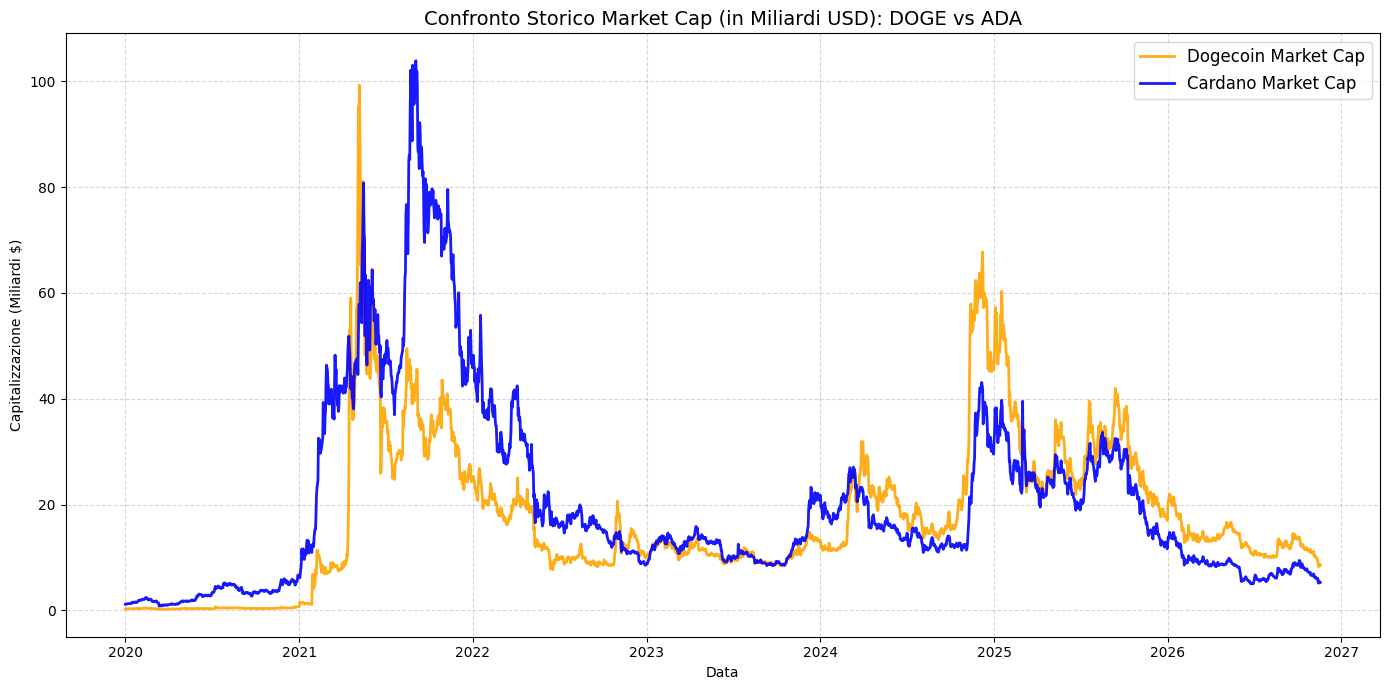

In [48]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yfinance as yf

# 1. Se hai già 'close' in memoria puoi saltare il download, altrimenti lo scarichiamo
tickers = ["DOGE-USD", "ADA-USD"]
df = yf.download(tickers, start="2020-01-01", auto_adjust=True)

if isinstance(df.columns, pd.MultiIndex):
  close = df["Close"]
else:
  close = df[[t for t in tickers if "Close" in t]]

# 2. Recuperiamo la supply circolante attuale tramite yfinance (con fallback di sicurezza)
ticker_doge = yf.Ticker("DOGE-USD")
ticker_ada = yf.Ticker("ADA-USD")

shares_doge = ticker_doge.info.get("sharesOutstanding", 145e9)
shares_ada = ticker_ada.info.get("sharesOutstanding", 35e9)

# 3. Calcolo della Market Cap (Prezzo * Circulating Supply) in miliardi di USD
market_cap = pd.DataFrame()
market_cap["DOGE-MCap"] = (close["DOGE-USD"] * shares_doge) / 1e9
market_cap["ADA-MCap"] = (close["ADA-USD"] * shares_ada) / 1e9

# 4. Visualizzazione Grafica
plt.figure(figsize=(14, 7))
plt.plot(
    market_cap.index,
    market_cap["DOGE-MCap"],
    label="Dogecoin Market Cap",
    color="orange",
    linewidth=2,
    alpha=0.9,
)
plt.plot(
    market_cap.index,
    market_cap["ADA-MCap"],
    label="Cardano Market Cap",
    color="blue",
    linewidth=2,
    alpha=0.9,
)

plt.title(
    "Confronto Storico Market Cap (in Miliardi USD): DOGE vs ADA", fontsize=14
)
plt.ylabel("Capitalizzazione (Miliardi $)")
plt.xlabel("Data")
plt.legend(fontsize=12)
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

[*********************100%***********************]  2 of 2 completed


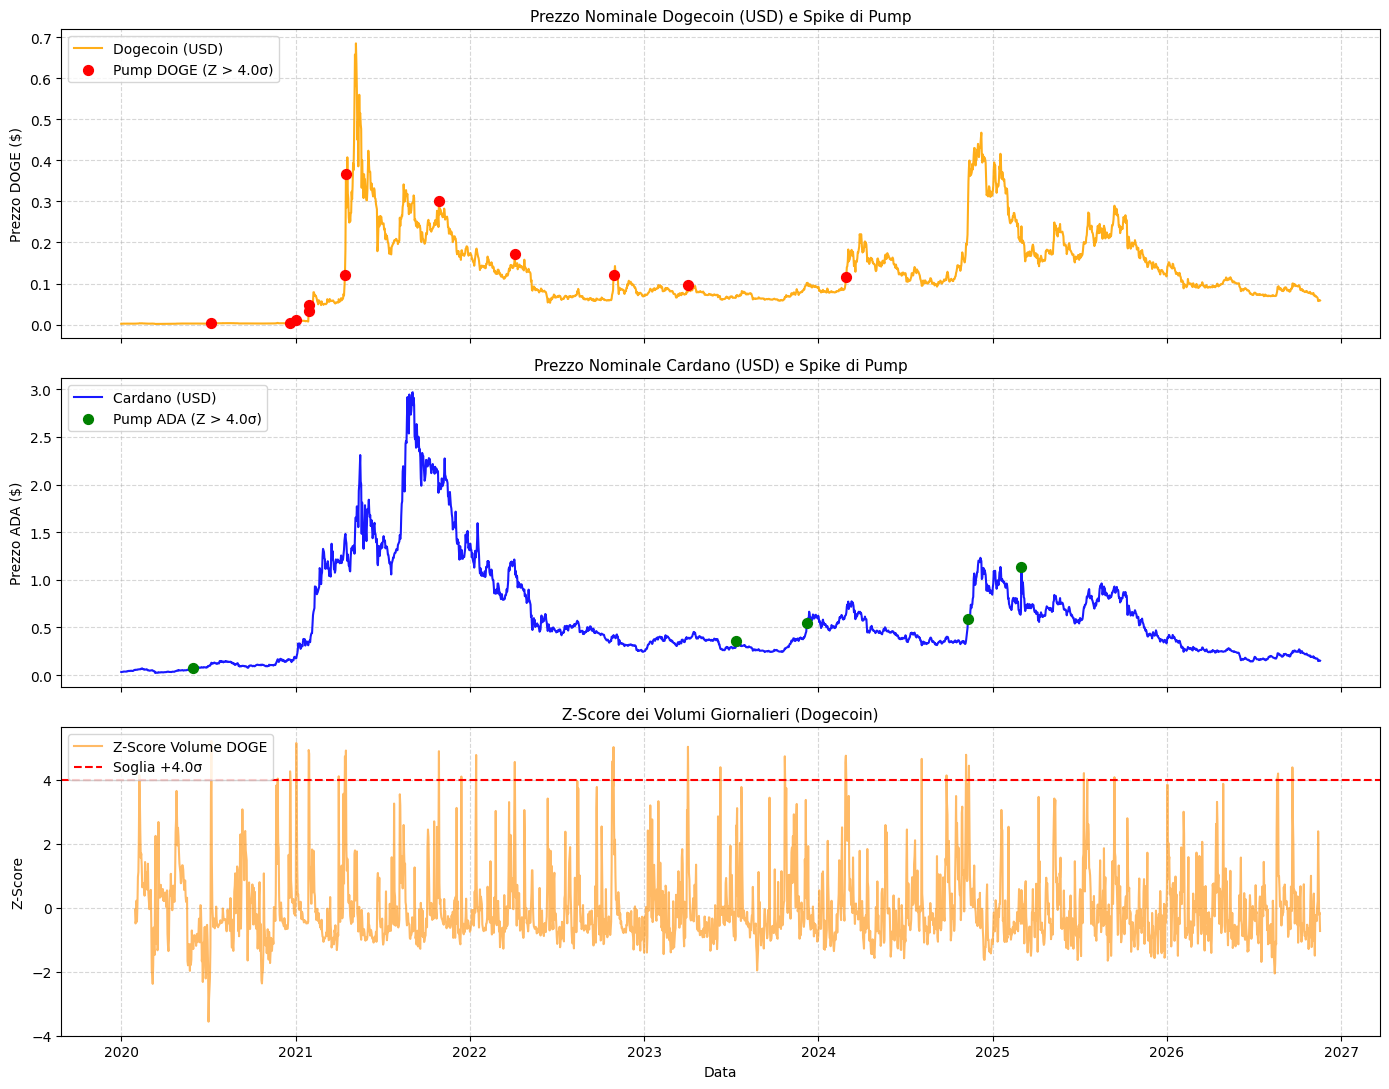

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yfinance as yf

# 1. Download dei dati storici per DOGE e ADA (se non già caricati)
tickers = ["DOGE-USD", "ADA-USD"]
df = yf.download(tickers, start="2020-01-01", auto_adjust=True)

if isinstance(df.columns, pd.MultiIndex):
  close = df["Close"]
  volume = df["Volume"]
else:
  close = df[[t for t in tickers if "Close" in t]]
  volume = df[[t for t in tickers if "Volume" in t]]

# 2. Calcoli statistici (Rendimenti, Curtosi e Z-Score dei volumi)
returns = np.log(close / close.shift(1))
window = 30
vol_sma = volume.rolling(window=window).mean()
vol_std = volume.rolling(window=window).std()
vol_zscore = (volume - vol_sma) / vol_std

volume_threshold = 4.0
return_threshold = 0.15

pump_mask_doge = (vol_zscore["DOGE-USD"] > volume_threshold) & (
    returns["DOGE-USD"] > return_threshold
)
pump_mask_ada = (vol_zscore["ADA-USD"] > volume_threshold) & (
    returns["ADA-USD"] > return_threshold
)

# 3. Visualizzazione con Subplot separati verticalmente (Asse Y indipendente per ciascuno)
fig, axes = plt.subplots(3, 1, figsize=(14, 11), sharex=True)

# Subplot 1: Prezzo Nominale Dogecoin con i suoi pump
axes[0].plot(
    close.index,
    close["DOGE-USD"],
    label="Dogecoin (USD)",
    color="orange",
    alpha=0.9,
)
doge_prices = close.loc[pump_mask_doge, "DOGE-USD"]
axes[0].scatter(
    doge_prices.index,
    doge_prices.values,
    color="red",
    s=50,
    zorder=5,
    label=f"Pump DOGE (Z > {volume_threshold}σ)",
)
axes[0].set_title(
    "Prezzo Nominale Dogecoin (USD) e Spike di Pump", fontsize=11
)
axes[0].set_ylabel("Prezzo DOGE ($)")
axes[0].legend(loc="upper left")
axes[0].grid(True, linestyle="--", alpha=0.5)

# Subplot 2: Prezzo Nominale Cardano con i suoi pump
axes[1].plot(
    close.index,
    close["ADA-USD"],
    label="Cardano (USD)",
    color="blue",
    alpha=0.9,
)
ada_prices = close.loc[pump_mask_ada, "ADA-USD"]
axes[1].scatter(
    ada_prices.index,
    ada_prices.values,
    color="green",
    s=50,
    zorder=5,
    label=f"Pump ADA (Z > {volume_threshold}σ)",
)
axes[1].set_title(
    "Prezzo Nominale Cardano (USD) e Spike di Pump", fontsize=11
)
axes[1].set_ylabel("Prezzo ADA ($)")
axes[1].legend(loc="upper left")
axes[1].grid(True, linestyle="--", alpha=0.5)

# Subplot 3: Z-Score dei volumi di Dogecoin (per mantenere il focus sull'anomalia)
axes[2].plot(
    vol_zscore.index,
    vol_zscore["DOGE-USD"],
    color="darkorange",
    alpha=0.6,
    label="Z-Score Volume DOGE",
)
axes[2].axhline(
    y=volume_threshold,
    color="red",
    linestyle="--",
    label=f"Soglia +{volume_threshold}σ",
)
axes[2].set_title("Z-Score dei Volumi Giornalieri (Dogecoin)", fontsize=11)
axes[2].set_ylabel("Z-Score")
axes[2].set_xlabel("Data")
axes[2].legend(loc="upper left")
axes[2].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

--- Analisi Dicembre 2020 (Vol. Z-Score > 4.0σ & Return > 15.0%) ---
Giorni di potenziale 'Pump' su Dogecoin a Dicembre 2020: 1


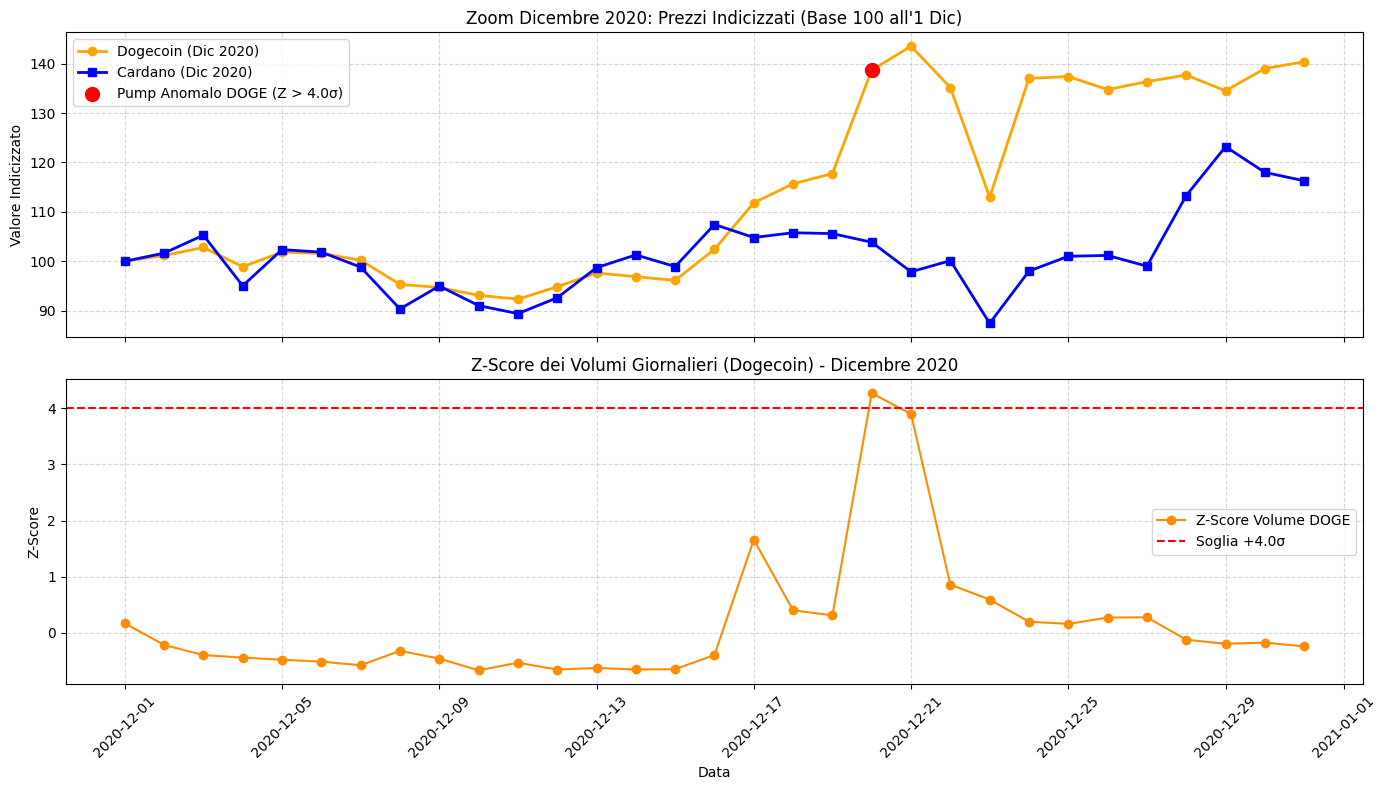

In [46]:
import matplotlib.pyplot as plt

# 1. Sfruttiamo i dataframe 'close' e 'volume' già esistenti in memoria
# Calcoliamo i rendimenti e lo z-score se non li avevi salvati
returns = np.log(close / close.shift(1))
window = 30
vol_sma = volume.rolling(window=window).mean()
vol_std = volume.rolling(window=window).std()
vol_zscore = (volume - vol_sma) / vol_std

# 2. Filtriamo rigorosamente solo il mese di Dicembre 2020
dec_mask = (close.index >= "2020-12-01") & (close.index <= "2020-12-31")

close_dec = close.loc[dec_mask]
returns_dec = returns.loc[dec_mask]
vol_zscore_dec = vol_zscore.loc[dec_mask]

# Normalizzazione Base 100 all'inizio di Dicembre 2020
norm_close_dec = (close_dec / close_dec.iloc[0]) * 100

# Applicazione del filtro di pump (Z-Score > 4σ & Return > 15%)
volume_threshold = 4.0
return_threshold = 0.15

pump_mask_dec = (vol_zscore_dec["DOGE-USD"] > volume_threshold) & (
    returns_dec["DOGE-USD"] > return_threshold
)

print(
    f"--- Analisi Dicembre 2020 (Vol. Z-Score > {volume_threshold}σ & Return >"
    f" {return_threshold*100}%) ---"
)
print(
    "Giorni di potenziale 'Pump' su Dogecoin a Dicembre 2020:"
    f" {pump_mask_dec.sum()}"
)

# 3. Visualizzazione Grafica Zoomata su Dicembre 2020
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

# Grafico Prezzi Indicizzati a Dicembre 2020
axes[0].plot(
    norm_close_dec.index,
    norm_close_dec["DOGE-USD"],
    label="Dogecoin (Dic 2020)",
    color="orange",
    marker="o",
    linewidth=2,
)
axes[0].plot(
    norm_close_dec.index,
    norm_close_dec["ADA-USD"],
    label="Cardano (Dic 2020)",
    color="blue",
    marker="s",
    linewidth=2,
)

# Evidenziamo eventuali giorni anomali a Dicembre
doge_pumps_dec = norm_close_dec.loc[pump_mask_dec, "DOGE-USD"]
if not doge_pumps_dec.empty:
  axes[0].scatter(
      doge_pumps_dec.index,
      doge_pumps_dec.values,
      color="red",
      s=100,
      zorder=5,
      label=f"Pump Anomalo DOGE (Z > {volume_threshold}σ)",
  )

axes[0].set_title(
    "Zoom Dicembre 2020: Prezzi Indicizzati (Base 100 all'1 Dic)", fontsize=12
)
axes[0].set_ylabel("Valore Indicizzato")
axes[0].legend()
axes[0].grid(True, linestyle="--", alpha=0.5)

# Sotto-grafico: Z-Score dei volumi a Dicembre 2020
axes[1].plot(
    vol_zscore_dec.index,
    vol_zscore_dec["DOGE-USD"],
    color="darkorange",
    marker="o",
    label="Z-Score Volume DOGE",
)
axes[1].axhline(
    y=volume_threshold,
    color="red",
    linestyle="--",
    label=f"Soglia +{volume_threshold}σ",
)
axes[1].set_title(
    "Z-Score dei Volumi Giornalieri (Dogecoin) - Dicembre 2020", fontsize=12
)
axes[1].set_ylabel("Z-Score")
axes[1].set_xlabel("Data")
axes[1].legend()
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

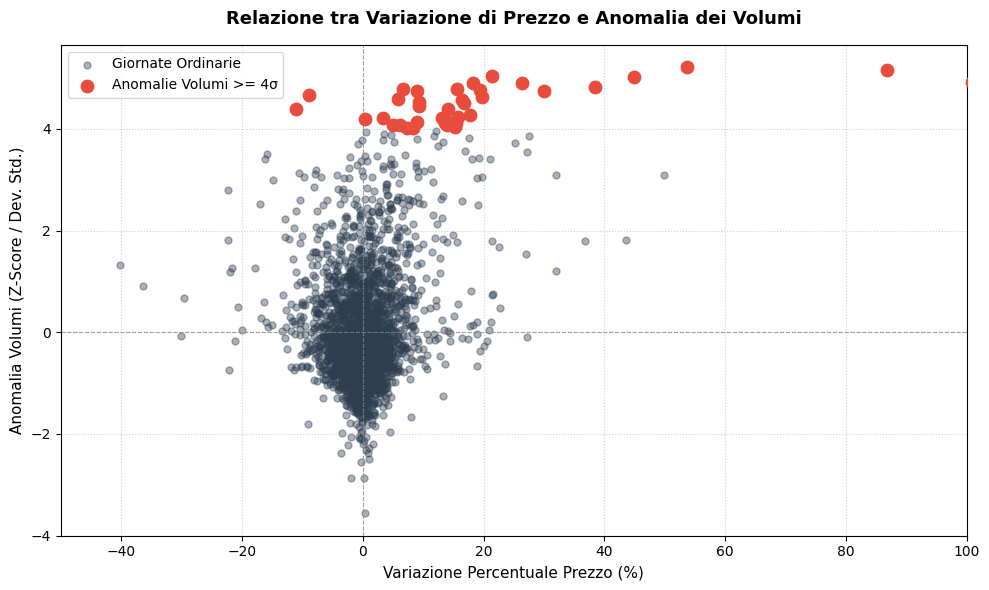

In [9]:
import matplotlib.pyplot as plt
import pandas as pd

fig, ax = plt.subplots(figsize=(10, 6))

x_col = "Price_Change_Pct"

# Controlliamo ed eventualmente calcoliamo 'Volume_ZScore' se non esiste nel DataFrame
if "Volume_ZScore" not in df.columns:
  vol_ma = df["Volume"].rolling(window=30).mean()
  vol_std = df["Volume"].rolling(window=30).std()
  df["Volume_ZScore"] = (df["Volume"] - vol_ma) / vol_std

y_col = "Volume_ZScore"

# Scatter plot di tutte le giornate ordinarie
ax.scatter(
    df[x_col],
    df[y_col],
    color="#2c3e50",
    alpha=0.4,
    s=25,
    label="Giornate Ordinarie",
)

# Evidenziamo in rosso i punti estremi con anomalie sui volumi >= 4 deviazioni standard
extreme_vol = df[df["Volume_ZScore"] >= 4.0]
ax.scatter(
    extreme_vol[x_col],
    extreme_vol[y_col],
    color="#e74c3c",
    s=80,
    zorder=5,
    label="Anomalie Volumi >= 4σ",
)

# Linee di riferimento per gli assi zero
ax.axhline(0, color="gray", linestyle="--", linewidth=0.8, alpha=0.7)
ax.axvline(0, color="gray", linestyle="--", linewidth=0.8, alpha=0.7)

# LIMITIAMO L'ASSE X TRA -50% E +100%
ax.set_xlim(-50, 100)

# Personalizzazione estetica
ax.set_title(
    (
        "Relazione tra Variazione di Prezzo e Anomalia dei Volumi"
    ),
    fontsize=13,
    fontweight="bold",
    pad=15,
)
ax.set_xlabel("Variazione Percentuale Prezzo (%)", fontsize=11)
ax.set_ylabel("Anomalia Volumi (Z-Score / Dev. Std.)", fontsize=11)

ax.legend(fontsize=10, loc="upper left")
ax.grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()

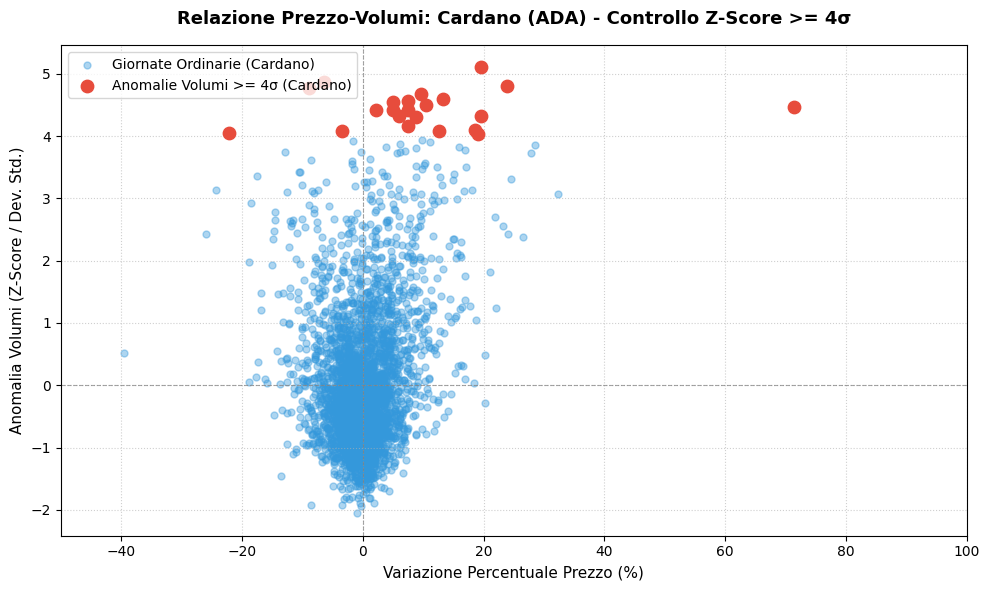

In [15]:
fig, ax = plt.subplots(figsize=(10, 6))

x_col = "Price_Change_Pct"

# Assicuriamoci che df_ada abbia già la colonna Price_Change_Pct calcolata
if "Price_Change_Pct" not in df_ada.columns:
  df_ada["Price_Change_Pct"] = df_ada["Close"].pct_change() * 100

# Controlliamo ed eventualmente calcoliamo 'Volume_ZScore' per Cardano
if "Volume_ZScore" not in df_ada.columns:
  vol_ma = df_ada["Volume"].rolling(window=30).mean()
  vol_std = df_ada["Volume"].rolling(window=30).std()
  df_ada["Volume_ZScore"] = (df_ada["Volume"] - vol_ma) / vol_std

y_col = "Volume_ZScore"

# Scatter plot di tutte le giornate ordinarie di Cardano
ax.scatter(
    df_ada[x_col],
    df_ada[y_col],
    color="#3498db",  # Blu tipico di Cardano per distinguerlo da Doge
    alpha=0.4,
    s=25,
    label="Giornate Ordinarie (Cardano)",
)

# Evidenziamo in rosso i punti estremi con anomalie sui volumi >= 4 deviazioni standard
extreme_vol_ada = df_ada[df_ada["Volume_ZScore"] >= 4.0]
ax.scatter(
    extreme_vol_ada[x_col],
    extreme_vol_ada[y_col],
    color="#e74c3c",
    s=80,
    zorder=5,
    label="Anomalie Volumi >= 4σ (Cardano)",
)

# Linee di riferimento per gli assi zero
ax.axhline(0, color="gray", linestyle="--", linewidth=0.8, alpha=0.7)
ax.axvline(0, color="gray", linestyle="--", linewidth=0.8, alpha=0.7)

# LIMITIAMO L'ASSE X TRA -50% E +100% per coerenza visiva
ax.set_xlim(-50, 100)

# Personalizzazione estetica
ax.set_title(
    "Relazione Prezzo-Volumi: Cardano (ADA) - Controllo Z-Score >= 4σ",
    fontsize=13,
    fontweight="bold",
    pad=15,
)
ax.set_xlabel("Variazione Percentuale Prezzo (%)", fontsize=11)
ax.set_ylabel("Anomalia Volumi (Z-Score / Dev. Std.)", fontsize=11)

ax.legend(fontsize=10, loc="upper left")
ax.grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()

La stragrande maggioranza degli outlier (4 deviazioni standard dalla media) indica grosse variazioni % di prezzo per Doge, mentre per cardano la maggiornaza sta tra 0 e 10%